In [15]:
from src import assemble_nodes
from src.orientation import get_angles, _correlate_angles, _make_rotating_masks
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize
from mpl_toolkits.axes_grid1 import ImageGrid
from src.graph import Tree, ImageSegmentation
import torchvision.transforms as T
import torch
import os
from torchvision.io import read_image
from torch.utils.data import Dataset, random_split
from resource.branch_dataset.dataset import BranchData
import sys

In [12]:
dataset = BranchData(
    os.path.join("resource", "branch_dataset")
)

loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=1,
    shuffle=True,
    num_workers=4
)

In [13]:
cnn = ImageSegmentation(kernel_size=3)
checkpoint = torch.load(os.path.join("model_checkpoints", f"checkpoint_nov_14_1chn_out_BCE.tar"))
cnn.load_state_dict(checkpoint["model_state_dict"])
cnn.eval();

In [17]:
accuracy = []
confidence = []
spot_check = {
    'original': [],
    'reconstruction': [],
    'accuracy': [],
    'confidence': [],
}

sys.setrecursionlimit(10000)

for batchid, (image, mask) in enumerate(loader, 0):
    model = Tree(image, cnn)
    approx = model.reconstruct_mask()

    e = np.abs(mask.squeeze(0).squeeze(0).numpy() - approx)
    s = np.sum(mask.squeeze(0).squeeze(0).numpy())
    a = 1 - (np.sum(e) / s)
    c = model.confidence
    
    accuracy.append(a)
    confidence.append(c)
    if batchid % 10 == 0:
        spot_check['original'].append(mask.squeeze(0).squeeze(0).numpy())
        spot_check['reconstruction'].append(approx)
        spot_check['accuracy'].append(a)
        spot_check['confidence'].append(c)

    print(f"Batch {batchid} accuracy {a}, confidence {c}")

c:\Users\wyatt\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\transforms\functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import pickle
with open("test_results_dec_10.pickle", 'wb') as file:
    pickle.dump({
        'accuracy': accuracy,
        'confidence': confidence,
        'check': spot_check
    }, file)

In [18]:
with open("test_results_dec_10.pickle", 'rb') as file:
    obj = pickle.load(file)
spot_check = obj["check"]

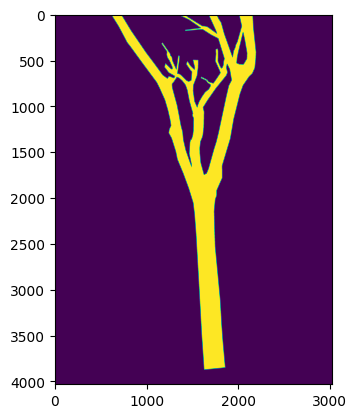

In [35]:
IDX = 0
plt.imshow(spot_check["original"][IDX].squeeze(0).squeeze(0).numpy())

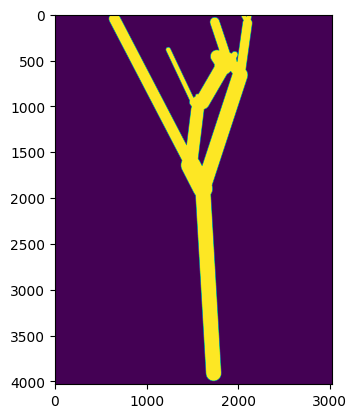

In [36]:
plt.imshow(spot_check["reconstruction"][IDX])